<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/pid_validation_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

P CONTROLLER - THEORETICAL VALIDATION
-------------------------------------
K = 1.0
tau = 1.0 s
Kp = 9.0
Ki = 0.0
Kd = 0.0
Setpoint = 1.0

EXPECTED RESULTS
Closed-loop time constant = 0.100 s
Final output = 0.900
Steady-state error = 10.0%

EULER SIMULATION RESULTS
------------------------
Simulation time step = 0.001 s
Simulated final output = 0.9000
Theoretical final output = 0.9000
Rise time (10%-90%) = 0.2190 s
Overshoot = 0.00%
Settling time (±2%) = 0.3900 s
Steady-state error = 10.00%


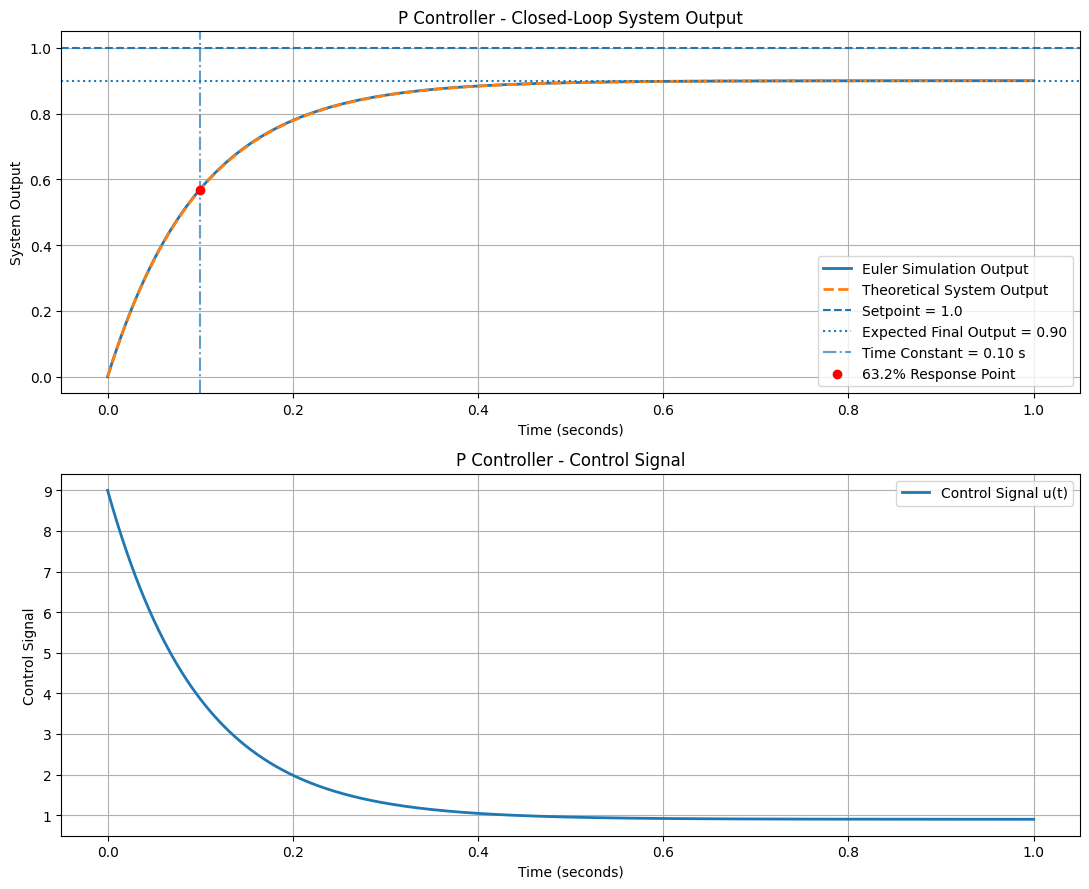

In [4]:

# File: pid_validation.py
# P Controller - Theoretical Validation + Euler Simulation

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# 1. SYSTEM PARAMETERS
# ==================================================

K = 1.0
tau = 1.0

Kp = 9.0
Ki = 0.0
Kd = 0.0

setpoint = 1.0

# ==================================================
# 2. THEORETICAL VALIDATION
# ==================================================

closed_loop_tau = tau / (1 + K * Kp)

final_output = (K * Kp * setpoint) / (1 + K * Kp)

steady_state_error = setpoint - final_output

print("P CONTROLLER - THEORETICAL VALIDATION")
print("-------------------------------------")
print(f"K = {K}")
print(f"tau = {tau} s")
print(f"Kp = {Kp}")
print(f"Ki = {Ki}")
print(f"Kd = {Kd}")
print(f"Setpoint = {setpoint}")

print("\nEXPECTED RESULTS")
print(f"Closed-loop time constant = {closed_loop_tau:.3f} s")
print(f"Final output = {final_output:.3f}")
print(f"Steady-state error = {steady_state_error * 100:.1f}%")

# ==================================================
# 3. SIMULATION SETTINGS
# ==================================================

dt = 0.001
t_end = 1.0

time = np.arange(0, t_end + dt, dt)

# Initialize arrays
y = np.zeros(len(time))
u = np.zeros(len(time))
error = np.zeros(len(time))

# ==================================================
# 4. EULER SIMULATION
# ==================================================

for i in range(1, len(time)):

    # Calculate error
    error[i-1] = setpoint - y[i-1]

    # P Controller
    u[i-1] = Kp * error[i-1]

    # First-order plant derivative
    dydt = (K * u[i-1] - y[i-1]) / tau

    # Euler integration
    y[i] = y[i-1] + dydt * dt

# Calculate last control values
error[-1] = setpoint - y[-1]
u[-1] = Kp * error[-1]

# ==================================================
# 5. THEORETICAL RESPONSE
# ==================================================

y_theoretical = final_output * (
    1 - np.exp(-time / closed_loop_tau)
)

# 63.2% response point
time_constant = closed_loop_tau
output_63 = final_output * (1 - np.exp(-1))

# ==================================================
# 6. PERFORMANCE MEASUREMENTS
# ==================================================

# Rise time: 10% to 90% of final output
level_10 = 0.10 * final_output
level_90 = 0.90 * final_output

idx_10 = np.where(y >= level_10)[0][0]
idx_90 = np.where(y >= level_90)[0][0]

rise_time = time[idx_90] - time[idx_10]

# Overshoot relative to final output
overshoot = max(
    0,
    (np.max(y) - final_output) / final_output * 100
)

# Settling time: remain within ±2% of final output
upper_band = final_output * 1.02
lower_band = final_output * 0.98

outside_band = np.where(
    (y > upper_band) | (y < lower_band)
)[0]

if len(outside_band) == 0:
    settling_time = 0.0
elif outside_band[-1] < len(time) - 1:
    settling_time = time[outside_band[-1] + 1]
else:
    settling_time = np.nan

simulation_error = abs(setpoint - y[-1])

# ==================================================
# 7. PRINT SIMULATION RESULTS
# ==================================================

print("\nEULER SIMULATION RESULTS")
print("------------------------")
print(f"Simulation time step = {dt} s")
print(f"Simulated final output = {y[-1]:.4f}")
print(f"Theoretical final output = {final_output:.4f}")
print(f"Rise time (10%-90%) = {rise_time:.4f} s")
print(f"Overshoot = {overshoot:.2f}%")
print(f"Settling time (±2%) = {settling_time:.4f} s")
print(f"Steady-state error = {simulation_error * 100:.2f}%")

# ==================================================
# 8. PLOTS
# ==================================================

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

# -------- Plot 1: System Output --------

axes[0].plot(
    time,
    y,
    label="Euler Simulation Output",
    linewidth=2
)

axes[0].plot(
    time,
    y_theoretical,
    "--",
    label="Theoretical System Output",
    linewidth=2
)

axes[0].axhline(
    setpoint,
    linestyle="--",
    label="Setpoint = 1.0"
)

axes[0].axhline(
    final_output,
    linestyle=":",
    label=f"Expected Final Output = {final_output:.2f}"
)

axes[0].axvline(
    time_constant,
    linestyle="-.",
    alpha=0.7,
    label=f"Time Constant = {time_constant:.2f} s"
)

axes[0].scatter(
    [time_constant],
    [output_63],
    color="red",
    zorder=5,
    label="63.2% Response Point"
)

axes[0].set_title(
    "P Controller - Closed-Loop System Output"
)

axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("System Output")

axes[0].grid(True)
axes[0].legend()

# -------- Plot 2: Control Signal --------

axes[1].plot(
    time,
    u,
    label="Control Signal u(t)",
    linewidth=2
)

axes[1].set_title(
    "P Controller - Control Signal"
)

axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Control Signal")

axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


VALIDATION CHECK 2 - PI THEORETICAL TEST
----------------------------------------
Kp = 1.0
Ki = 1.0
Natural frequency = 1.000 rad/s
Damping ratio = 1.000

EXPECTED VALUES
Natural frequency = 1.000 rad/s
Damping ratio = 1.000

SIMULATION RESULTS
Final output = 1.000000
Steady-state error = 0.000000%
Overshoot = 0.0000%

CHECK 2 STATUS: PASS

VALIDATION CHECK 3 - ZERO STEADY-STATE ERROR
--------------------------------------------

PI Controller A
Kp = 1.0, Ki = 1.0
Final output = 1.000000
Steady-state error = 0.000000%

PI Controller B
Kp = 2.0, Ki = 0.5
Final output = 0.999992
Steady-state error = 0.000755%

CHECK 3 STATUS: PASS

FINAL VALIDATION
----------------
Check 2: PASS
Check 3: PASS


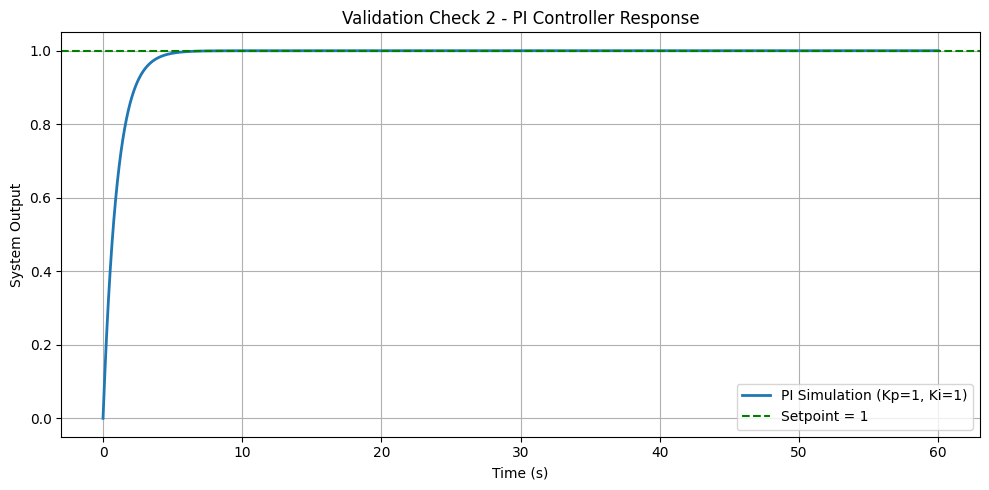

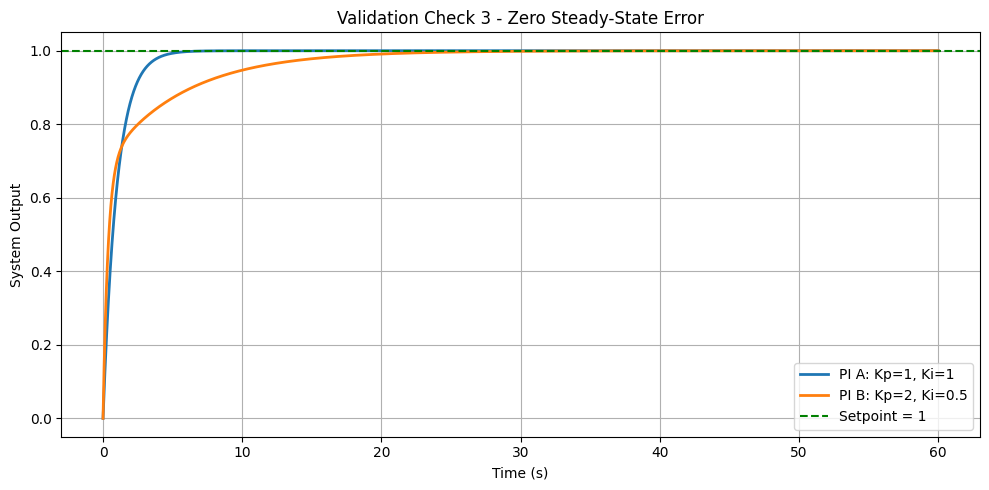

In [6]:

# PI Controller - Validation Checks 2 and 3
# ENCS4380 Homework 2

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PLANT PARAMETERS
# ==========================================

K = 1.0
tau = 1.0
setpoint = 1.0

dt = 0.001
t_end = 60.0

time = np.arange(0, t_end + dt, dt)


# ==========================================
# 2. PI SIMULATION FUNCTION
# ==========================================

def simulate_pi(Kp, Ki):

    y = np.zeros(len(time))
    u = np.zeros(len(time))
    error = np.zeros(len(time))

    integral = 0.0

    for i in range(len(time) - 1):

        error[i] = setpoint - y[i]

        # Integral action
        integral += error[i] * dt

        # PI controller
        u[i] = Kp * error[i] + Ki * integral

        # First-order plant
        dydt = (K * u[i] - y[i]) / tau

        # Euler integration
        y[i + 1] = y[i] + dydt * dt

    error[-1] = setpoint - y[-1]
    u[-1] = Kp * error[-1] + Ki * integral

    steady_state_error = (
        abs(setpoint - y[-1]) / abs(setpoint) * 100
    )

    overshoot = max(
        0,
        (np.max(y) - setpoint) / abs(setpoint) * 100
    )

    return y, u, steady_state_error, overshoot


# ==========================================
# 3. VALIDATION CHECK 2
# PI: Kp = 1, Ki = 1
# ==========================================

Kp_2 = 1.0
Ki_2 = 1.0

omega_n = np.sqrt((K * Ki_2) / tau)

zeta = (1 + K * Kp_2) / (
    2 * np.sqrt(tau * K * Ki_2)
)

y_2, u_2, error_2, overshoot_2 = simulate_pi(Kp_2, Ki_2)

print("VALIDATION CHECK 2 - PI THEORETICAL TEST")
print("----------------------------------------")
print(f"Kp = {Kp_2}")
print(f"Ki = {Ki_2}")
print(f"Natural frequency = {omega_n:.3f} rad/s")
print(f"Damping ratio = {zeta:.3f}")

print("\nEXPECTED VALUES")
print("Natural frequency = 1.000 rad/s")
print("Damping ratio = 1.000")

print("\nSIMULATION RESULTS")
print(f"Final output = {y_2[-1]:.6f}")
print(f"Steady-state error = {error_2:.6f}%")
print(f"Overshoot = {overshoot_2:.4f}%")

check_2_pass = (
    abs(omega_n - 1.0) < 0.001
    and abs(zeta - 1.0) < 0.001
)

print("\nCHECK 2 STATUS:",
      "PASS" if check_2_pass else "FAIL")


# ==========================================
# 4. VALIDATION CHECK 3
# TEST ZERO STEADY-STATE ERROR
# ==========================================

# First PI controller
Kp_3a = 1.0
Ki_3a = 1.0

y_3a, u_3a, error_3a, overshoot_3a = simulate_pi(
    Kp_3a, Ki_3a
)

# Second PI controller
Kp_3b = 2.0
Ki_3b = 0.5

y_3b, u_3b, error_3b, overshoot_3b = simulate_pi(
    Kp_3b, Ki_3b
)

print("\nVALIDATION CHECK 3 - ZERO STEADY-STATE ERROR")
print("--------------------------------------------")

print("\nPI Controller A")
print(f"Kp = {Kp_3a}, Ki = {Ki_3a}")
print(f"Final output = {y_3a[-1]:.6f}")
print(f"Steady-state error = {error_3a:.6f}%")

print("\nPI Controller B")
print(f"Kp = {Kp_3b}, Ki = {Ki_3b}")
print(f"Final output = {y_3b[-1]:.6f}")
print(f"Steady-state error = {error_3b:.6f}%")

tolerance = 0.01

check_3_pass = (
    error_3a < tolerance
    and error_3b < tolerance
)

print("\nCHECK 3 STATUS:",
      "PASS" if check_3_pass else "FAIL")

print("\nFINAL VALIDATION")
print("----------------")
print("Check 2:", "PASS" if check_2_pass else "FAIL")
print("Check 3:", "PASS" if check_3_pass else "FAIL")


# ==========================================
# 5. PLOT - VALIDATION CHECK 2
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    time, y_2,
    label="PI Simulation (Kp=1, Ki=1)",
    linewidth=2
)

plt.axhline(
    setpoint,
    color="green",
    linestyle="--",
    label="Setpoint = 1"
)

plt.title("Validation Check 2 - PI Controller Response")
plt.xlabel("Time (s)")
plt.ylabel("System Output")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 6. PLOT - VALIDATION CHECK 3
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    time, y_3a,
    label="PI A: Kp=1, Ki=1",
    linewidth=2
)

plt.plot(
    time, y_3b,
    label="PI B: Kp=2, Ki=0.5",
    linewidth=2
)

plt.axhline(
    setpoint,
    color="green",
    linestyle="--",
    label="Setpoint = 1"
)

plt.title("Validation Check 3 - Zero Steady-State Error")
plt.xlabel("Time (s)")
plt.ylabel("System Output")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
